# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [79]:
class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def value(self):
        if self.rank == "A":
            return 11
        elif self.rank in ("J", "Q", "K"):
            return 10
        else:
            return int(self.rank)

    def __str__(self):
        return f"{self.rank} of {self.suit}."
    

In [80]:
#testing
card1 = Card("K", "Hearts")
card2 = Card("A", "Spades")
card3 = Card("8", "Clubs")

print(card1)
print(card1.value())
print(card2.value())
print(card3.value())

K of Hearts.
10
11
8


In [108]:
import random #needed to shuffle cards

class Deck:
    def __init__(self, n_decks = 6):
        self.cards = []
        self.needs_shuffle = False
        self.n_decks = n_decks

        ranks = ["2", "3", "4", "5", "6", "7", "8",
                 "9", "10", "J", "Q", "K", "A"]
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]

        for deck_no in range(n_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(rank, suit))
        #insert the plastic card in random location
        self.shuffle()
        position = random.randint(0, len(self.cards))
        self.cards.insert(position, None)
                    
    #here, it shuffles the cards and returns it
    def shuffle(self):
        return random.shuffle(self.cards)

    #here, it will draw the card
    def draw(self):
        while self.cards: #repeat while the list has items
            card = self.cards.pop() #removes the last item

            if card is None: #if we found the plastic marker, shuffle it again
                self.needs_shuffle = True 
            else:
                return card

        raise RuntimeError("There is no playable cards remain in the deck")
            


In [97]:
#testing
deck = Deck(6)
print(len(deck.cards))

small_deck = Deck(1)
print(len(small_deck.cards))
print(small_deck.cards[0])

313
53
9 of Clubs.


In [98]:
#shuffling cards - here it just changes the card's order but not the exact no of cards.
deck = Deck(6)
deck.shuffle()

print(deck.cards[1])
print(len(deck.cards))

3 of Spades.
313


In [99]:
#testing for draw()
deck = Deck(6)
deck.cards = [Card("7", "Hearts"), None]

print(deck.draw())         
print(deck.needs_shuffle) 
print(len(deck.cards)) 

7 of Hearts.
True
0


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [ ]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def total(self):
        pass

    def is_bust(self):
        pass

    def clear(self):
        pass


class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def wants_hit(self):
        pass

    def observe(self, card):
        pass

    def reset_count(self):
        pass


class DealerPlayer(Player):
    def wants_hit(self):
        pass


class HumanPlayer(Player):
    def wants_hit(self):
        pass


class CountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold
        self.count = 0

    def observe(self, card):
        pass

    def reset_count(self):
        pass

    def wants_hit(self):
        pass


class StandAt16Player(Player):
    def wants_hit(self):
        pass


class Game:
    def __init__(self, players, n_decks=6, bet=10, verbose=True):
        self.players = players
        self.n_decks = n_decks
        self.bet = bet
        self.verbose = verbose
        self.deck = None
        self.dealer = None

    def log(self, message):
        pass

    def notify(self, card):
        pass

    def deal_card(self, player, visible=True):
        pass

    def prepare_round(self):
        pass

    def is_blackjack(self, hand):
        pass

    def play_round(self):
        pass

    def play(self, rounds=50, tracked_player=None):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [103]:
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def total(self):
        total = 0
        aces = 0

        for card in self.cards:
            total += card.value()

            if card.rank == "A":
                aces += 1

        #if needed change aces from 11 to 1
        while total > 21 and aces > 0:
            total -= 10
            aces -= 1
        return total

    def is_bust(self):
        return self.total() > 21

    def clear(self):
        self.cards.clear()

class Player:
    def __init__(self, name, chips = 100):
        self.name = name
        self.chips = chips
        self.hand = Hand()

    def wants_hit(self):
        raise NotImplementedError("A player must have a strategy")

    def observe(self, card): #herem ordinary players do not count cards
        pass

    def reset_count(self): #here, this will be overridden when counting players later
        pass

class DealerPlayer(Player):
    def wants_hit(self):
        #here, if hit on 16 or less and stand on 17 or more
        return self.hand.total() < 17

class HumanPlayer(Player):
    def wants_hit(self):
        if self.hand.total() >= 21:
            return False
        print(f"\n{self.name}'s hand:")

        for card in self.hand.cards:
            print(card)
        print("Total: ", self.hand.total())

        while True:
            choice = input("Do u wanna Hit or Stand? Enter h or s: ").strip().lower()

            if choice == "h":
                return True
            elif choice == "s":
                return False
            else:
                print("Please enter h or s only")



In [104]:
#testing for Hand class
hand = Hand()
hand.add_card(Card("A", "Spades"))
hand.add_card(Card("A", "Hearts"))
hand.add_card(Card("9", "Clubs"))

print(hand.total())   
print(hand.is_bust())  

hand.add_card(Card("K", "Diamonds"))
print(hand.total())    

hand.add_card(Card("2", "Clubs"))
print(hand.total())   
print(hand.is_bust())

hand.clear()
print(hand.cards)      
print(hand.total())   

21
False
21
23
True
[]
0


In [105]:
#testing for DealerPlayer
bot = DealerPlayer("Computer 1", 150)

bot.hand.add_card(Card("9", "Hearts"))
bot.hand.add_card(Card("5", "Spades"))

print(bot.name, bot.chips) 
print(bot.hand.total())    

print(bot.wants_hit())     

bot.hand.add_card(Card("A", "Spades"))

print(bot.hand.total())     
print(bot.wants_hit())   


Computer 1 150
14
True
15
True


In [106]:
#testing for HumanPlayer classes
human = HumanPlayer("Prabin", 100)
human.hand.add_card(Card("10", "Hearts"))
human.hand.add_card(Card("5", "Clubs"))

print(human.wants_hit())


Prabin's hand:
10 of Hearts.
5 of Clubs.
Total:  15


Do u wanna Hit or Stand? Enter h or s:  h


True


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [109]:
class Game:
    def __init__(self, players, n_decks=6, bet=10, verbose=True):
        self.players = players
        self.n_decks = n_decks
        self.bet = bet
        self.verbose = verbose

        self.deck = Deck(n_decks)
        self.dealer = DealerPlayer("Dealer", 0)

    def log(self, message):
        if self.verbose:
            print(message)

    def notify(self, card):
        # Every player sees each exposed card exactly once.
        for player in self.players:
            player.observe(card)

    def deal_card(self, player, visible=True):
        card = self.deck.draw()
        player.hand.add_card(card)

        if visible:
            self.notify(card)
            self.log(f"{player.name} receives {card}")

        return card

    def prepare_round(self):
        # Reserve enough cards to avoid exhausting the shoe mid-round.
        reserve = 22 * (len(self.players) + 1)
        available = sum(card is not None for card in self.deck.cards)

        if self.deck.needs_shuffle or available < reserve:
            self.deck = Deck(self.n_decks)

            for player in self.players:
                player.reset_count()

            self.log("Shoe rebuilt and shuffled.")

        for player in self.players:
            player.hand.clear()

        self.dealer.hand.clear()

    def is_blackjack(self, hand):
        return len(hand.cards) == 2 and hand.total() == 21

    def play_round(self):
        active = [
            player for player in self.players
            if player.chips >= self.bet
        ]

        if not active:
            return False

        self.prepare_round()

        # Deduct bets before dealing.
        for player in active:
            player.chips -= self.bet

        # First card: everyone receives an exposed card.
        for player in active:
            self.deal_card(player)

        self.deal_card(self.dealer)

        # Second card: dealer's card remains hidden.
        for player in active:
            self.deal_card(player)

        hidden_card = self.deal_card(self.dealer, visible=False)
        dealer_blackjack = self.is_blackjack(self.dealer.hand)

        # A dealer blackjack ends play before players take extra cards.
        if not dealer_blackjack:
            for player in active:
                while player.hand.total() < 21:
                    if not player.wants_hit():
                        break

                    self.deal_card(player)

                self.log(
                    f"{player.name}'s total: {player.hand.total()}"
                )

        # Reveal the hidden card only now.
        self.notify(hidden_card)
        self.log(f"Dealer reveals {hidden_card}")

        # Dealer draws only if someone still needs a comparison.
        needs_comparison = any(
            not player.hand.is_bust()
            and not self.is_blackjack(player.hand)
            for player in active
        )

        if not dealer_blackjack and needs_comparison:
            while self.dealer.wants_hit():
                self.deal_card(self.dealer)

        dealer_total = self.dealer.hand.total()
        self.log(f"Dealer's total: {dealer_total}")

        for player in active:
            total = player.hand.total()
            blackjack = self.is_blackjack(player.hand)

            if player.hand.is_bust():
                outcome = "loses: bust"

            elif dealer_blackjack:
                if blackjack:
                    player.chips += self.bet
                    outcome = "ties"
                else:
                    outcome = "loses to dealer blackjack"

            elif blackjack:
                # Return stake plus a profit of 1.5 times the bet.
                player.chips += 2.5 * self.bet
                outcome = "wins with blackjack"

            elif self.dealer.hand.is_bust() or total > dealer_total:
                # Return stake plus an equal-sized profit.
                player.chips += 2 * self.bet
                outcome = "wins"

            elif total == dealer_total:
                player.chips += self.bet
                outcome = "ties"

            else:
                outcome = "loses"

            self.log(
                f"{player.name} {outcome}; chips: {player.chips}"
            )

        return True

    def play(self, rounds=50, tracked_player=None):
        rounds_played = 0

        for number in range(rounds):
            if (
                tracked_player is not None
                and tracked_player.chips < self.bet
            ):
                break

            self.log(f"\n--- Round {number + 1} ---")

            if not self.play_round():
                break

            rounds_played += 1

        return rounds_played

In [110]:
players = [
    DealerPlayer("Computer 1", 100),
    DealerPlayer("Computer 2", 100),
    DealerPlayer("Computer 3", 100)
]

game = Game(players, n_decks=6, bet=10, verbose=True)
rounds_played = game.play(rounds=3)

print("\nRounds played:", rounds_played)

for player in players:
    print(player.name, "final chips:", player.chips)


--- Round 1 ---
Computer 1 receives 9 of Hearts.
Computer 2 receives J of Spades.
Computer 3 receives K of Spades.
Dealer receives A of Spades.
Computer 1 receives K of Clubs.
Computer 2 receives J of Clubs.
Computer 3 receives K of Diamonds.
Computer 1's total: 19
Computer 2's total: 20
Computer 3's total: 20
Dealer reveals 3 of Hearts.
Dealer receives 6 of Clubs.
Dealer's total: 20
Computer 1 loses; chips: 90
Computer 2 ties; chips: 100
Computer 3 ties; chips: 100

--- Round 2 ---
Computer 1 receives 5 of Hearts.
Computer 2 receives K of Diamonds.
Computer 3 receives 6 of Clubs.
Dealer receives 10 of Diamonds.
Computer 1 receives Q of Diamonds.
Computer 2 receives 2 of Spades.
Computer 3 receives K of Hearts.
Computer 1 receives 9 of Clubs.
Computer 1's total: 24
Computer 2 receives A of Diamonds.
Computer 2 receives 3 of Clubs.
Computer 2 receives 10 of Clubs.
Computer 2's total: 26
Computer 3 receives Q of Diamonds.
Computer 3's total: 26
Dealer reveals 4 of Diamonds.
Dealer's tot

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [111]:
class CountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold
        self.count = 0

    def observe(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            self.count += 1
        elif card.rank in ["10", "J", "Q", "K", "A"]:
            self.count -= 1

    def reset_count(self):
        self.count = 0

    def wants_hit(self):
        return self.hand.total() < 21 and self.count < self.threshold

In [113]:
counter = CountingPlayer("Counter", threshold=0)

counter.observe(Card("K", "Hearts"))
print(counter.count)       
print(counter.wants_hit()) 

counter.observe(Card("5", "Clubs"))
print(counter.count)       
print(counter.wants_hit())  

counter.observe(Card("8", "Spades"))
print(counter.count)       

counter.reset_count()
print(counter.count)       

-1
True
0
False
0
0


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [116]:
starting_chips = 100
bet = 10

counter = CountingPlayer(
    "Counter",
    chips=starting_chips,
    threshold=0
)

players = [
    counter,
    DealerPlayer("Computer 1", starting_chips),
    DealerPlayer("Computer 2", starting_chips),
    DealerPlayer("Computer 3", starting_chips)
]

game = Game(players, n_decks=6, bet=bet, verbose=False)

rounds_played = game.play(
    rounds=50,
    tracked_player=counter
)

net_winnings = counter.chips - starting_chips

print("Rounds played:", rounds_played)
print("Starting chips:", starting_chips)
print("Final chips:", counter.chips)
print("Net winnings:", net_winnings)

Rounds played: 14
Starting chips: 100
Final chips: 5.0
Net winnings: -95.0


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


In [118]:
import numpy as np
import matplotlib.pyplot as plt


def simulate_games(threshold, n_games=100, rounds=50,
                   starting_chips=100, bet=10):

    final_chips = []
    rounds_played = []

    for game_number in range(n_games):
        counter = CountingPlayer(
            "Counter",
            chips=starting_chips,
            threshold=threshold
        )

        players = [
            counter,
            DealerPlayer("Computer 1", starting_chips),
            DealerPlayer("Computer 2", starting_chips),
            DealerPlayer("Computer 3", starting_chips)
        ]

        game = Game(
            players,
            n_decks=6,
            bet=bet,
            verbose=False
        )

        played = game.play(
            rounds=rounds,
            tracked_player=counter
        )

        final_chips.append(counter.chips)
        rounds_played.append(played)

    return final_chips, rounds_played

In [120]:
final_chips, rounds_played = simulate_games(threshold=0)

net_winnings = np.array(final_chips) - 100
rounds_played = np.array(rounds_played)

# here its Total net profit divided by the total number of rounds actually played.
average_per_round = np.sum(net_winnings) / np.sum(rounds_played)

# Here, its the Variation in final net winnings across games.
std_net_winnings = np.std(net_winnings, ddof=1)

print("Number of games:", len(final_chips))
print("Average final chips:", np.mean(final_chips))
print("Average net winnings per game:", np.mean(net_winnings))
print("Average net winnings per round:", average_per_round)
print("Standard deviation of net winnings:", std_net_winnings)

print("Probability of net winning:", np.mean(net_winnings > 0))
print("Probability of net losing:", np.mean(net_winnings < 0))
print("Probability of breaking even:", np.mean(net_winnings == 0))

print("Games completing 50 rounds:", np.sum(rounds_played == 50))

Number of games: 100
Average final chips: 5.95
Average net winnings per game: -94.05
Average net winnings per round: -3.408843783979703
Standard deviation of net winnings: 13.682824889974182
Probability of net winning: 0.0
Probability of net losing: 1.0
Probability of breaking even: 0.0
Games completing 50 rounds: 10


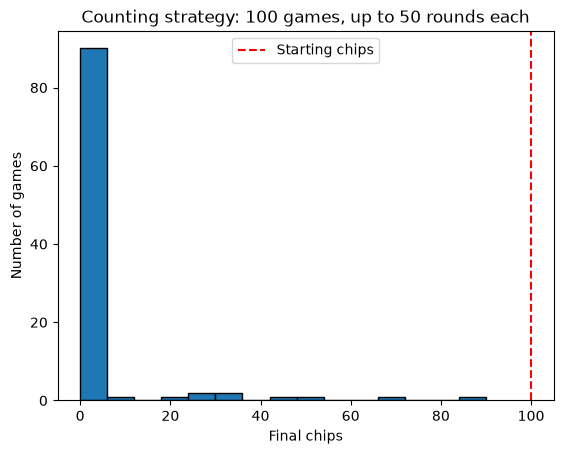

In [121]:
plt.hist(final_chips, bins=15, edgecolor="black")
plt.axvline(
    100,
    color="red",
    linestyle="--",
    label="Starting chips"
)
plt.xlabel("Final chips")
plt.ylabel("Number of games")
plt.title("Counting strategy: 100 games, up to 50 rounds each")
plt.legend()
plt.show()

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

Threshold -10 | Net/round: -2.069 | Net/game: -75.75 | SD: 42.98 | P(win): 0.09 | P(loss): 0.91


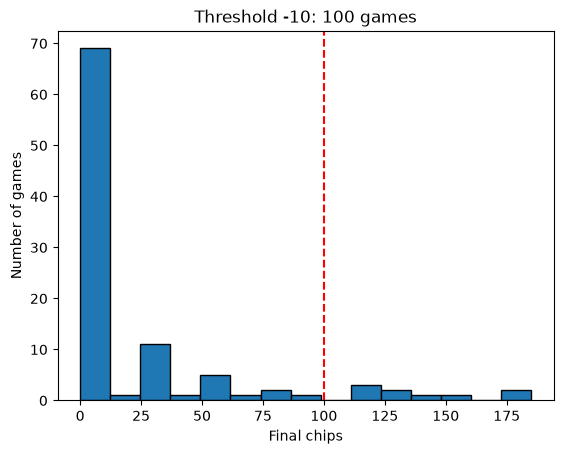

Threshold  -5 | Net/round: -2.248 | Net/game: -77.75 | SD: 36.81 | P(win): 0.05 | P(loss): 0.94


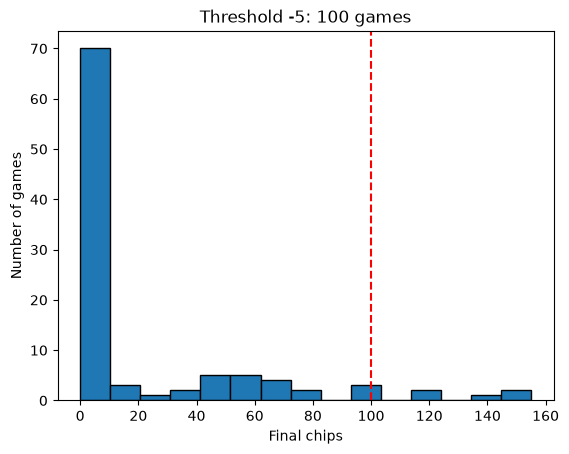

Threshold   0 | Net/round: -3.502 | Net/game: -91.90 | SD: 18.99 | P(win): 0.00 | P(loss): 0.99


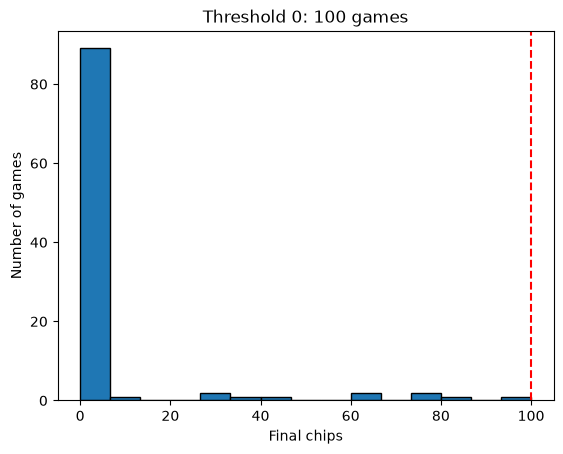

Threshold   5 | Net/round: -5.097 | Net/game: -97.55 | SD: 4.11 | P(win): 0.00 | P(loss): 1.00


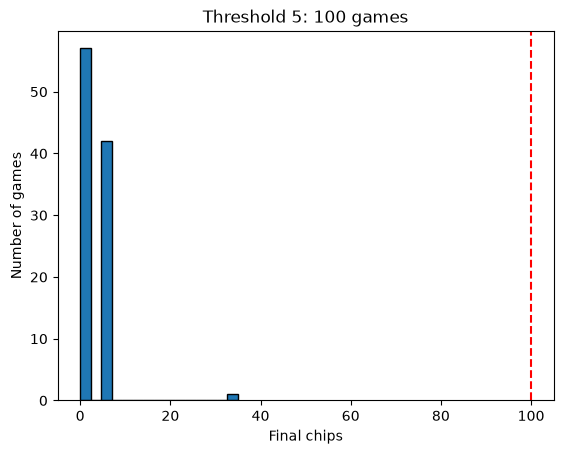

Threshold  10 | Net/round: -6.233 | Net/game: -98.35 | SD: 2.36 | P(win): 0.00 | P(loss): 1.00


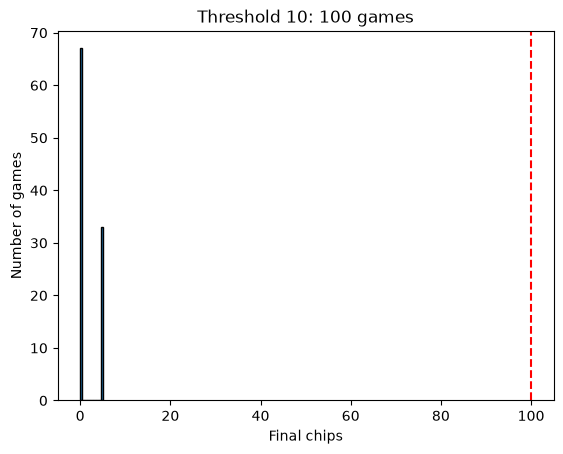

In [122]:
thresholds = [-10, -5, 0, 5, 10]
results = []

for threshold in thresholds:
    final_chips, played = simulate_games(threshold=threshold)

    net = np.array(final_chips) - 100
    played = np.array(played)

    average_per_round = np.sum(net) / np.sum(played)
    average_per_game = np.mean(net)
    std_winnings = np.std(net, ddof=1)
    probability_win = np.mean(net > 0)
    probability_loss = np.mean(net < 0)

    results.append({
        "threshold": threshold,
        "average_per_round": average_per_round,
        "average_per_game": average_per_game,
        "std": std_winnings,
        "probability_win": probability_win,
        "probability_loss": probability_loss
    })

    print(
        f"Threshold {threshold:3d} | "
        f"Net/round: {average_per_round:.3f} | "
        f"Net/game: {average_per_game:.2f} | "
        f"SD: {std_winnings:.2f} | "
        f"P(win): {probability_win:.2f} | "
        f"P(loss): {probability_loss:.2f}"
    )

    plt.figure()
    plt.hist(final_chips, bins=15, edgecolor="black")
    plt.axvline(100, color="red", linestyle="--")
    plt.xlabel("Final chips")
    plt.ylabel("Number of games")
    plt.title(f"Threshold {threshold}: 100 games")
    plt.show()

In [124]:
best = max(results, key=lambda result: result["average_per_round"])

print("Best tested threshold:", best["threshold"])
print("Average net winnings per round:", best["average_per_round"])

Best tested threshold: -10
Average net winnings per round: -2.0685417804478425


Threshold −10 performed best among the tested values, with an average loss of approximately 2.07 chips per round and 75.75 chips per game. Its observed probability of a net win was 9%, so “best” here means the smallest observed loss, not a profitable or proven optimal strategy

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [127]:
class StandAt16Player(Player):
    def wants_hit(self):
        return self.hand.total() < 16


def simulate_new_strategy(n_games=100, rounds=50,
                          starting_chips=100, bet=10):
    final_chips = []
    rounds_played = []

    for game_number in range(n_games):
        strategy_player = StandAt16Player(
            "Stand at 16", starting_chips
        )

        players = [
            strategy_player,
            DealerPlayer("Computer 1", starting_chips),
            DealerPlayer("Computer 2", starting_chips),
            DealerPlayer("Computer 3", starting_chips)
        ]

        game = Game(
            players, n_decks=6, bet=bet, verbose=False
        )

        played = game.play(
            rounds=rounds,
            tracked_player=strategy_player
        )

        final_chips.append(strategy_player.chips)
        rounds_played.append(played)

    return final_chips, rounds_played

In [129]:
test_player = StandAt16Player("Test")

test_player.hand.add_card(Card("10", "Hearts"))
test_player.hand.add_card(Card("5", "Clubs"))
assert test_player.wants_hit() is True  # Total 15

test_player.hand.add_card(Card("A", "Spades"))
assert test_player.hand.total() == 16
assert test_player.wants_hit() is False

print("Strategy tests passed.")

Strategy tests passed.


In [130]:
starting_chips = 100

count_chips, count_rounds = simulate_games(
    threshold=best["threshold"],
    starting_chips=starting_chips
)

new_chips, new_rounds = simulate_new_strategy(
    starting_chips=starting_chips
)

count_net = np.array(count_chips) - starting_chips
new_net = np.array(new_chips) - starting_chips

count_rate = np.sum(count_net) / np.sum(count_rounds)
new_rate = np.sum(new_net) / np.sum(new_rounds)

print("New strategy: stand at 16")
print("Average net winnings per game:", np.mean(new_net))
print("Average net winnings per round:", new_rate)
print("Standard deviation of net winnings:", np.std(new_net, ddof=1))
print("Probability of net winning:", np.mean(new_net > 0))
print("Probability of net losing:", np.mean(new_net < 0))
print("Probability of breaking even:", np.mean(new_net == 0))

print("\nCounting threshold:", best["threshold"])
print("Counting strategy net winnings per round:", count_rate)
print("New strategy net winnings per round:", new_rate)
print("Difference (new minus counting):", new_rate - count_rate)

if new_rate > count_rate:
    print("The new strategy performed better in this simulation.")
elif new_rate < count_rate:
    print("The new strategy performed worse in this simulation.")
else:
    print("Both strategies had the same observed winnings per round.")

New strategy: stand at 16
Average net winnings per game: -9.55
Average net winnings per round: -0.20384204909284953
Standard deviation of net winnings: 62.49482806883731
Probability of net winning: 0.46
Probability of net losing: 0.52
Probability of breaking even: 0.02

Counting threshold: -10
Counting strategy net winnings per round: -1.6029528078038493
New strategy net winnings per round: -0.20384204909284953
Difference (new minus counting): 1.3991107587109997
The new strategy performed better in this simulation.


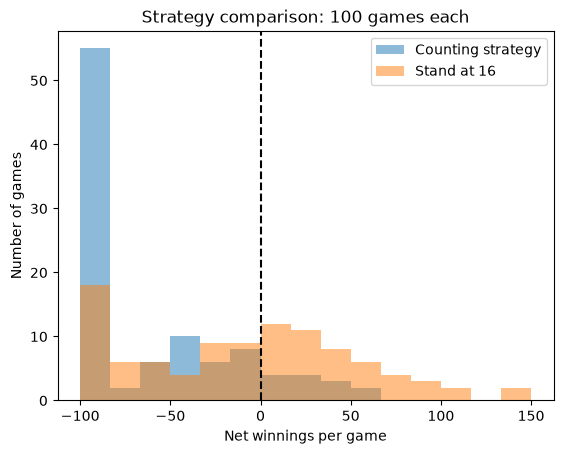

In [131]:
bins = np.histogram_bin_edges(
    np.concatenate([count_net, new_net]),
    bins=15
)

plt.hist(count_net, bins=bins, alpha=0.5, label="Counting strategy")
plt.hist(new_net, bins=bins, alpha=0.5, label="Stand at 16")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Net winnings per game")
plt.ylabel("Number of games")
plt.title("Strategy comparison: 100 games each")
plt.legend()
plt.show()

The alternative strategy hits below 17 and stands at 17 or above. It lost approximately 0.59 chips per round, compared with 2.07 for the best tested counting threshold—an improvement of about 1.48 chips per round. Across 100 games, it won overall in 32%, lost in 67%, and broke even in 1%; these results show improved observed performance, not guaranteed profitability